#**Information Retrieval - Demonstration**

# Importing Data

In [2]:
!wget -q https://ai2-semanticscholar-cord-19.s3-us-west-2.amazonaws.com/2022-06-02/metadata.csv \
    -O /content/cord19_metadata.csv

import pandas as pd

df = pd.read_csv(
    '/content/cord19_metadata.csv',
    usecols=['title', 'abstract'],
    low_memory=False
)


df = df.dropna(subset=['abstract'])

df['title'] = df['title'].fillna('')

df = df.sample(
    n=10000,
    random_state=42
).reset_index(drop=True)

# Create the document collection
df['document'] = df['title'] + ' ' + df['abstract']

# Save the 10,000-document collection
df.to_csv('/content/cord19_10000.csv', index=False)

# Display information
print("======================================")
print("       CORD-19 IR COLLECTION")
print("======================================")
print("Number of documents :", len(df))
print("Columns             :", list(df.columns))

print("\nSample documents:")
display(df[['title', 'abstract']].head())

       CORD-19 IR COLLECTION
Number of documents : 10000
Columns             : ['title', 'abstract', 'document']

Sample documents:


,title,abstract
0,Maternal and infant outcomes of full-term preg...,OBJECTIVE: To investigate the maternal and inf...
1,COVID-19: Characteristics and Therapeutics,Novel coronavirus (COVID-19 or 2019-nCoV or SA...
2,Multilingualism on the Berlin Stage: The Influ...,"This article analyses how language choice, lin..."
3,Psychometric properties of the French and Engl...,BACKGROUND: The Protective Behavioural Strateg...
4,Epidemiological changes of common respiratory ...,A variety of non‐pharmaceutical interventions ...


In [3]:
# Original documents

documents = df['document'].fillna('').tolist()

print("Number of documents:", len(documents))

print("\nSample document:")
print(documents[0][:1000])

Number of documents: 10000

Sample document:
Maternal and infant outcomes of full-term pregnancy combined with COVID-2019 in Wuhan, China: retrospective case series OBJECTIVE: To investigate the maternal and infant outcomes of full-term pregnant patients in Wuhan, China, who were infected with 2019 severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2) that is responsible for coronavirus disease 2019 (COVID-2019). DESIGN: Retrospective case series. SETTING: The Central Hospitals of Wuhan, Tongji Medical College, Huazhong University of Science and Technology in Wuhan, China. PARTICIPANTS: Twenty one full-term pregnant patients who were admitted to the Central Hospital of Wuhan, Tongji Medical College, Huazhong University of Science and Technology, confirmed SARS-CoV-2 infection and COVID-2019 with laboratorial and clinical methods, were reviewed by our medical team, and the data were collected from January 20, 2020 to February 29, 2020. MAIN CLINICAL DATA COLLECTION: Clinical data

# Pre-processing

# Lower Case

In [4]:
def lowercase(text):
    return text.lower()


lowercase_documents = [
    lowercase(doc)
    for doc in documents
]

print("Before:")
print(documents[0][:500])

print("\nAfter Lowercasing:")
print(lowercase_documents[0][:500])

Before:
Maternal and infant outcomes of full-term pregnancy combined with COVID-2019 in Wuhan, China: retrospective case series OBJECTIVE: To investigate the maternal and infant outcomes of full-term pregnant patients in Wuhan, China, who were infected with 2019 severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2) that is responsible for coronavirus disease 2019 (COVID-2019). DESIGN: Retrospective case series. SETTING: The Central Hospitals of Wuhan, Tongji Medical College, Huazhong University o

After Lowercasing:
maternal and infant outcomes of full-term pregnancy combined with covid-2019 in wuhan, china: retrospective case series objective: to investigate the maternal and infant outcomes of full-term pregnant patients in wuhan, china, who were infected with 2019 severe acute respiratory syndrome coronavirus 2 (sars-cov-2) that is responsible for coronavirus disease 2019 (covid-2019). design: retrospective case series. setting: the central hospitals of wuhan, tongji medical c

# Remove Punctuation

In [5]:
# REMOVE PUNCTUATION

import string

def remove_punctuation(text):
    return text.translate(
        str.maketrans('', '', string.punctuation)
    )


punctuation_removed_documents = [
    remove_punctuation(doc)
    for doc in documents
]

print("Before:")
print(documents[0][:500])

print("\nAfter Removing Punctuation:")
print(punctuation_removed_documents[0][:500])

Before:
Maternal and infant outcomes of full-term pregnancy combined with COVID-2019 in Wuhan, China: retrospective case series OBJECTIVE: To investigate the maternal and infant outcomes of full-term pregnant patients in Wuhan, China, who were infected with 2019 severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2) that is responsible for coronavirus disease 2019 (COVID-2019). DESIGN: Retrospective case series. SETTING: The Central Hospitals of Wuhan, Tongji Medical College, Huazhong University o

After Removing Punctuation:
Maternal and infant outcomes of fullterm pregnancy combined with COVID2019 in Wuhan China retrospective case series OBJECTIVE To investigate the maternal and infant outcomes of fullterm pregnant patients in Wuhan China who were infected with 2019 severe acute respiratory syndrome coronavirus 2 SARSCoV2 that is responsible for coronavirus disease 2019 COVID2019 DESIGN Retrospective case series SETTING The Central Hospitals of Wuhan Tongji Medical College Huaz

# Expand Contractions

In [6]:
!pip install -q contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.8/114.8 kB 8.5 MB/s eta 0:00:00


In [7]:
import contractions

def expand_contractions(text):
    return contractions.fix(text)

sent = "This product isn't bad and I don't dislike it."

expanded_sent = expand_contractions(sent)

print("Before:")
print(sent)

print("\nAfter:")
print(expanded_sent)

Before:
This product isn't bad and I don't dislike it.

After:
This product is not bad and I do not dislike it.


# Remove Numbers

In [8]:
import re

def remove_numbers(text):
    # only spare digits touching a LETTER (covid19, h1n1),
    return re.sub(r'(?<![A-Za-z])\d[\d.,-]*\d(?![A-Za-z])|(?<![A-Za-z])\d(?![A-Za-z])', '', text)

sent = "COVID-19 was reported in 2020 in 150 countries."

clean_sent = remove_numbers(sent)

print("Before:")
print(sent)

print("\nAfter:")
print(clean_sent)

Before:
COVID-19 was reported in 2020 in 150 countries.

After:
COVID- was reported in  in  countries.


# Remove Tags

In [9]:
import re

def remove_tags(text):
    return re.sub(r'<[^>]+>', '', text)

sent = "<p>This is a <b>good</b> product.</p>"

clean_sent = remove_tags(sent)

print("Before:")
print(sent)

print("\nAfter removing tags:")
print(clean_sent)

Before:
<p>This is a <b>good</b> product.</p>

After removing tags:
This is a good product.


# Spell Correct

In [10]:
!pip install -q autocorrect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 622.8/622.8 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [11]:
# SPELL CORRECT

from autocorrect import Speller

spell = Speller(lang='en')

def spell_correct(text):
    return spell(text)

sent = "This prodcut is realy good."

corrected_sent = spell_correct(sent)

print("Before:")
print(sent)

print("\nAfter Spell Correction:")
print(corrected_sent)

Before:
This prodcut is realy good.

After Spell Correction:
This product is really good.


# Tokenization

In [12]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import word_tokenize

def tokenize(text):
    return word_tokenize(text)


tokenized_documents = [
    tokenize(doc)
    for doc in punctuation_removed_documents
]

print("Original:")
print(punctuation_removed_documents[0][:500])

print("\nTokens:")
print(tokenized_documents[0][:100])

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original:
Maternal and infant outcomes of fullterm pregnancy combined with COVID2019 in Wuhan China retrospective case series OBJECTIVE To investigate the maternal and infant outcomes of fullterm pregnant patients in Wuhan China who were infected with 2019 severe acute respiratory syndrome coronavirus 2 SARSCoV2 that is responsible for coronavirus disease 2019 COVID2019 DESIGN Retrospective case series SETTING The Central Hospitals of Wuhan Tongji Medical College Huazhong University of Science and Technol

Tokens:
['Maternal', 'and', 'infant', 'outcomes', 'of', 'fullterm', 'pregnancy', 'combined', 'with', 'COVID2019', 'in', 'Wuhan', 'China', 'retrospective', 'case', 'series', 'OBJECTIVE', 'To', 'investigate', 'the', 'maternal', 'and', 'infant', 'outcomes', 'of', 'fullterm', 'pregnant', 'patients', 'in', 'Wuhan', 'China', 'who', 'were', 'infected', 'with', '2019', 'severe', 'acute', 'respiratory', 'syndrome', 'coronavirus', '2', 'SARSCoV2', 'that', 'is', 'responsible', 'for', 'coronavir

In [13]:
# sentence tokenize



# Stop word Removal

In [14]:
nltk.download('stopwords', quiet=True)

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print("Number of stop words:", len(stop_words))
print(list(stop_words)[:20])


def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in stop_words
    ]


stopword_removed_documents = [
    remove_stopwords(doc)
    for doc in tokenized_documents
]

print("\n")
print("Before:")
print(tokenized_documents[0][:50])

print("\nAfter Stop-word Removal:")
print(stopword_removed_documents[0][:50])

Number of stop words: 198
['should', "they'd", 't', 'he', 'did', 'so', 'to', 'nor', 'was', 'haven', "should've", "you've", 'or', 'when', 'because', 'how', "mightn't", 'yourself', "doesn't", "it's"]


Before:
['Maternal', 'and', 'infant', 'outcomes', 'of', 'fullterm', 'pregnancy', 'combined', 'with', 'COVID2019', 'in', 'Wuhan', 'China', 'retrospective', 'case', 'series', 'OBJECTIVE', 'To', 'investigate', 'the', 'maternal', 'and', 'infant', 'outcomes', 'of', 'fullterm', 'pregnant', 'patients', 'in', 'Wuhan', 'China', 'who', 'were', 'infected', 'with', '2019', 'severe', 'acute', 'respiratory', 'syndrome', 'coronavirus', '2', 'SARSCoV2', 'that', 'is', 'responsible', 'for', 'coronavirus', 'disease', '2019']

After Stop-word Removal:
['Maternal', 'infant', 'outcomes', 'fullterm', 'pregnancy', 'combined', 'COVID2019', 'Wuhan', 'China', 'retrospective', 'case', 'series', 'OBJECTIVE', 'To', 'investigate', 'maternal', 'infant', 'outcomes', 'fullterm', 'pregnant', 'patients', 'Wuhan', 'China', 'i

# Is stopword removal always good?

In [15]:
from nltk.tokenize import word_tokenize

sent = "This product is not bad at all."



# Is there any other ways to select stopwords?

In [16]:
from collections import Counter

# Combine all tokens from all documents
all_tokens = [
    word
    for doc in tokenized_documents
    for word in doc
]

word_frequency = Counter(all_tokens)

# Display the 20 most frequent words
print("Top 20 most frequent words:\n")

for word, frequency in word_frequency.most_common(20):
    print(f"{word:<20} {frequency}")

Top 20 most frequent words:

the                  101818
of                   89462
and                  84426
in                   50585
to                   49241
a                    32020
with                 24552
for                  22956
COVID19              18783
The                  17299
is                   15156
were                 15141
was                  14096
on                   13483
that                 13319
patients             11964
as                   11004
by                   10617
from                 9653
are                  8713


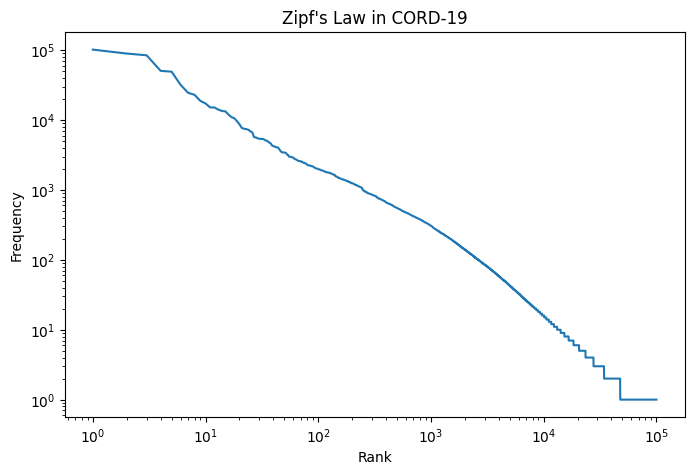

In [17]:
import matplotlib.pyplot as plt

# Sort frequencies from highest to lowest
frequencies = sorted(
    word_frequency.values(),
    reverse=True
)

ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))

plt.loglog(ranks, frequencies)

plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.title("Zipf's Law in CORD-19")

plt.show()

In [18]:
stopword_removed_documents = [
    remove_stopwords(doc)
    for doc in tokenized_documents
]

In [19]:
all_tokens_without_stopwords = [
    word
    for doc in stopword_removed_documents
    for word in doc
]

word_frequency_without_stopwords = Counter(
    all_tokens_without_stopwords
)

print("Top 20 most frequent words after stop-word removal:\n")

for word, frequency in word_frequency_without_stopwords.most_common(20):
    print(f"{word:<20} {frequency}")

Top 20 most frequent words after stop-word removal:

COVID19              18783
The                  17299
patients             11964
study                7258
pandemic             6896
health               5642
We                   5477
SARSCoV2             5392
disease              5107
In                   5078
This                 4883
A                    4747
data                 4235
infection            4045
using                3671
2020                 3452
clinical             3440
risk                 3429
care                 3419
used                 3205


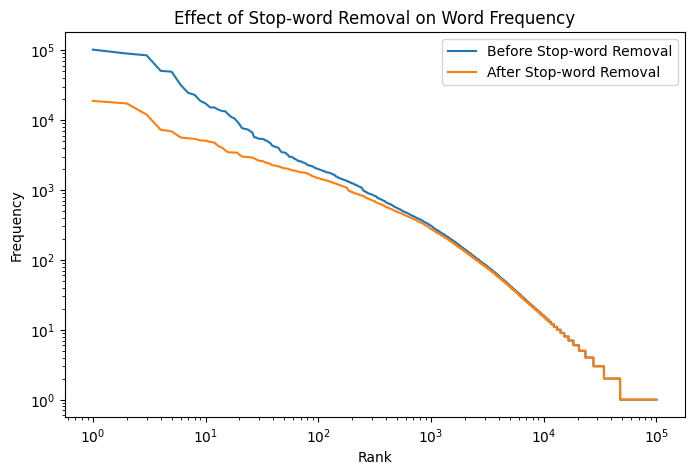

In [20]:
frequencies_before = sorted(
    word_frequency.values(),
    reverse=True
)

frequencies_after = sorted(
    word_frequency_without_stopwords.values(),
    reverse=True
)

plt.figure(figsize=(8, 5))

plt.loglog(
    range(1, len(frequencies_before) + 1),
    frequencies_before,
    label="Before Stop-word Removal"
)

plt.loglog(
    range(1, len(frequencies_after) + 1),
    frequencies_after,
    label="After Stop-word Removal"
)

plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.title("Effect of Stop-word Removal on Word Frequency")
plt.legend()

plt.show()

# Stemming

*   Porter - Moderate, widely used
*   Lancaster - Aggressive stemming
*   Snowball - Improved Porter, multilingual


In [21]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def stem_words(tokens):
    return [
        stemmer.stem(word)
        for word in tokens
    ]


stemmed_documents = [
    stem_words(doc)
    for doc in stopword_removed_documents
]

print("Before Stemming:")
print(stopword_removed_documents[0][:50])

print("\nAfter Stemming:")
print(stemmed_documents[0][:50])

Before Stemming:
['Maternal', 'infant', 'outcomes', 'fullterm', 'pregnancy', 'combined', 'COVID2019', 'Wuhan', 'China', 'retrospective', 'case', 'series', 'OBJECTIVE', 'To', 'investigate', 'maternal', 'infant', 'outcomes', 'fullterm', 'pregnant', 'patients', 'Wuhan', 'China', 'infected', '2019', 'severe', 'acute', 'respiratory', 'syndrome', 'coronavirus', '2', 'SARSCoV2', 'responsible', 'coronavirus', 'disease', '2019', 'COVID2019', 'DESIGN', 'Retrospective', 'case', 'series', 'SETTING', 'The', 'Central', 'Hospitals', 'Wuhan', 'Tongji', 'Medical', 'College', 'Huazhong']

After Stemming:
['matern', 'infant', 'outcom', 'fullterm', 'pregnanc', 'combin', 'covid2019', 'wuhan', 'china', 'retrospect', 'case', 'seri', 'object', 'to', 'investig', 'matern', 'infant', 'outcom', 'fullterm', 'pregnant', 'patient', 'wuhan', 'china', 'infect', '2019', 'sever', 'acut', 'respiratori', 'syndrom', 'coronaviru', '2', 'sarscov2', 'respons', 'coronaviru', 'diseas', '2019', 'covid2019', 'design', 'retrospect

# Use Lancaster and Porter stemmer

# Lemmatization

In [22]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN


def lemmatize_words(tokens):
    tagged = nltk.pos_tag(tokens)
    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in tagged
    ]


lemmatized_documents = [
    lemmatize_words(doc)
    for doc in stopword_removed_documents
]

print("Before Lemmatization:")
print(stopword_removed_documents[0][:50])

print("\nAfter Lemmatization:")
print(lemmatized_documents[0][:50])

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Before Lemmatization:
['Maternal', 'infant', 'outcomes', 'fullterm', 'pregnancy', 'combined', 'COVID2019', 'Wuhan', 'China', 'retrospective', 'case', 'series', 'OBJECTIVE', 'To', 'investigate', 'maternal', 'infant', 'outcomes', 'fullterm', 'pregnant', 'patients', 'Wuhan', 'China', 'infected', '2019', 'severe', 'acute', 'respiratory', 'syndrome', 'coronavirus', '2', 'SARSCoV2', 'responsible', 'coronavirus', 'disease', '2019', 'COVID2019', 'DESIGN', 'Retrospective', 'case', 'series', 'SETTING', 'The', 'Central', 'Hospitals', 'Wuhan', 'Tongji', 'Medical', 'College', 'Huazhong']

After Lemmatization:
['Maternal', 'infant', 'outcome', 'fullterm', 'pregnancy', 'combine', 'COVID2019', 'Wuhan', 'China', 'retrospective', 'case', 'series', 'OBJECTIVE', 'To', 'investigate', 'maternal', 'infant', 'outcome', 'fullterm', 'pregnant', 'patient', 'Wuhan', 'China', 'infect', '2019', 'severe', 'acute', 'respiratory', 'syndrome', 'coronavirus', '2', 'SARSCoV2', 'responsible', 'coronavirus', 'disease', '20

# Compare stemming and lemmatization

# Create a common preprocessing function

In [25]:
# Apply preprocessing to all documents

processed_documents = [
    preprocess_text(doc)
    for doc in df['document']
]

print("Preprocessing completed!")
print("Number of documents:", len(processed_documents))

Preprocessing completed!
Number of documents: 10000


In [26]:
# Compare original and processed document

print("Original Document:")
print(df['document'].iloc[0][:1000])

print("\n" + "="*80 + "\n")

print("Processed Document:")
print(processed_documents[0][:100])

Original Document:
Maternal and infant outcomes of full-term pregnancy combined with COVID-2019 in Wuhan, China: retrospective case series OBJECTIVE: To investigate the maternal and infant outcomes of full-term pregnant patients in Wuhan, China, who were infected with 2019 severe acute respiratory syndrome coronavirus 2 (SARS-CoV-2) that is responsible for coronavirus disease 2019 (COVID-2019). DESIGN: Retrospective case series. SETTING: The Central Hospitals of Wuhan, Tongji Medical College, Huazhong University of Science and Technology in Wuhan, China. PARTICIPANTS: Twenty one full-term pregnant patients who were admitted to the Central Hospital of Wuhan, Tongji Medical College, Huazhong University of Science and Technology, confirmed SARS-CoV-2 infection and COVID-2019 with laboratorial and clinical methods, were reviewed by our medical team, and the data were collected from January 20, 2020 to February 29, 2020. MAIN CLINICAL DATA COLLECTION: Clinical data had been collecting using

In [27]:
processed_text_documents = [
    ' '.join(tokens)
    for tokens in processed_documents
]

In [28]:
print("Number of documents:", len(processed_text_documents))
print("\nSample document:")
print(processed_text_documents[0][:500])

Number of documents: 10000

Sample document:
maternal infant outcome fullterm pregnancy combine covid wuhan china retrospective case series objective investigate maternal infant outcome fullterm pregnant patient wuhan china infect severe acute respiratory syndrome coronavirus sarscov responsible coronavirus disease covid design retrospective case series set central hospital wuhan tongji medical college huazhong university science technology wuhan china participant twenty one fullterm pregnant patient admitted central hospital wuhan tongji 


# Binary Retrieval Model

Represents documents and queries using a binary term-document matrix.

Each term is assigned 1 if it occurs in a document and 0 otherwise.

Retrieval based only on the presence or absence of terms, without considering their frequency or importance.

*   1 --> Term is present in the document
*   0 --> Term is absent from the document

Documents containing more query terms are ranked higher.

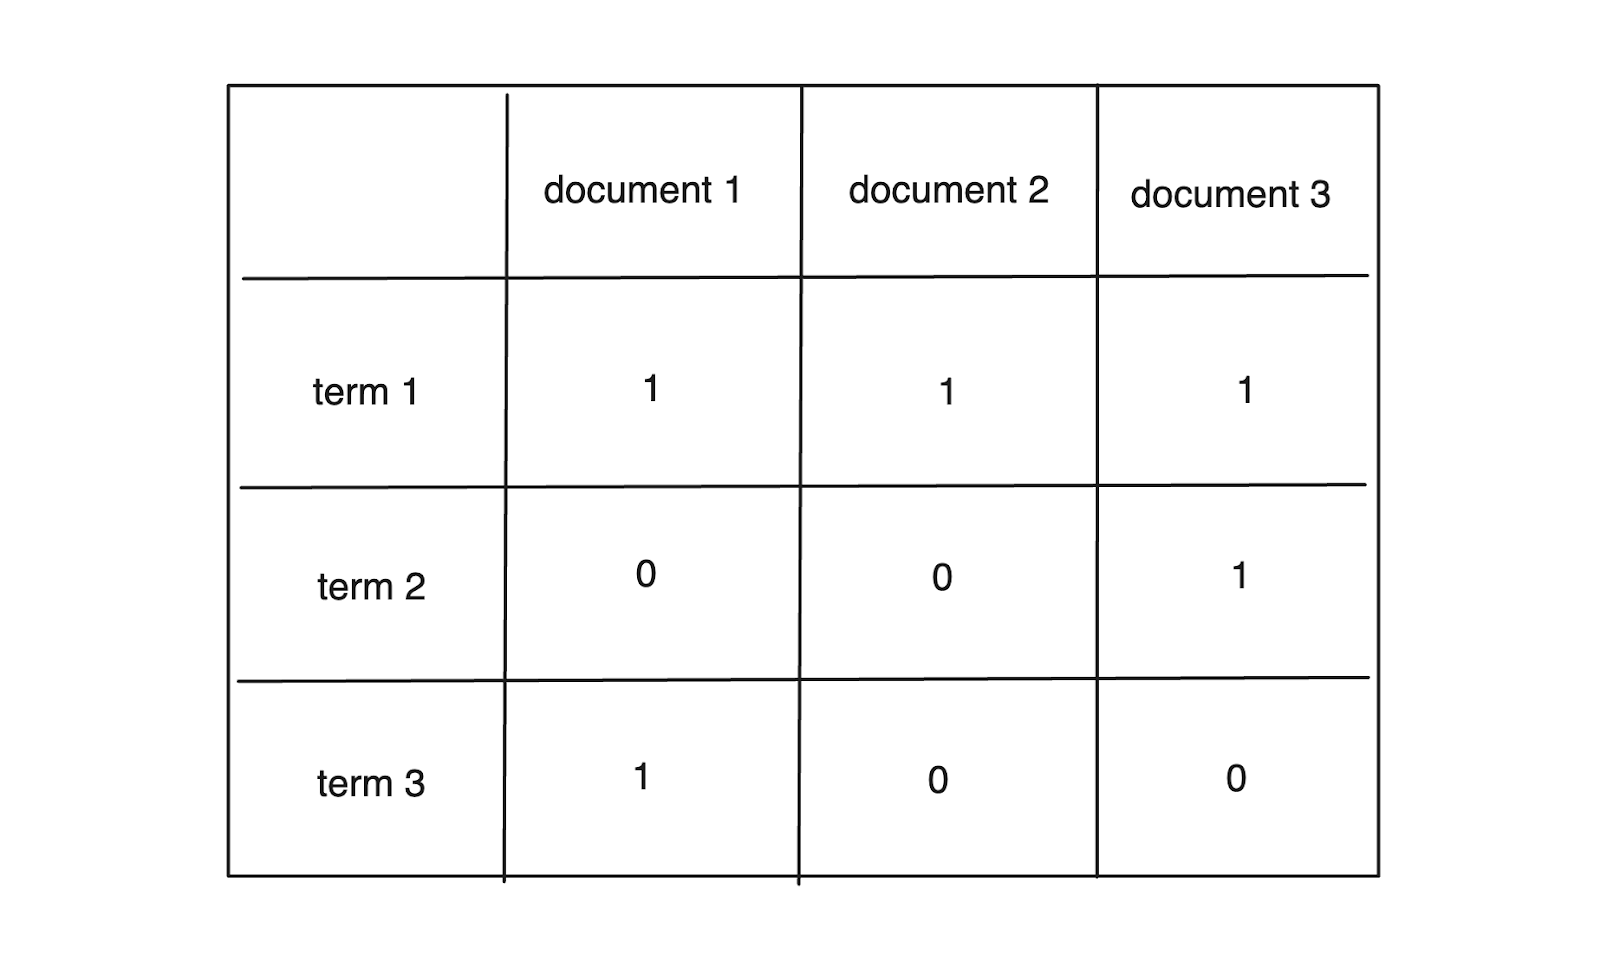

In [29]:
from sklearn.feature_extraction.text import CountVectorizer

# Binary term-document matrix
binary_vectorizer = CountVectorizer(
    binary=True
)

binary_matrix = binary_vectorizer.fit_transform(
    processed_text_documents
)

print("Matrix shape:", binary_matrix.shape)

Matrix shape: (10000, 65380)


In [30]:
print("Number of terms:", len(binary_vectorizer.vocabulary_))

print("\nSample vocabulary:")
print(list(binary_vectorizer.vocabulary_.keys())[:20])

Number of terms: 65380

Sample vocabulary:
['maternal', 'infant', 'outcome', 'fullterm', 'pregnancy', 'combine', 'covid', 'wuhan', 'china', 'retrospective', 'case', 'series', 'objective', 'investigate', 'pregnant', 'patient', 'infect', 'severe', 'acute', 'respiratory']


In [31]:
query = "covid vaccine"

In [32]:
query_vector = binary_vectorizer.transform([query])

print("Query vector shape:", query_vector.shape)

Query vector shape: (1, 65380)


In [33]:
binary_scores = binary_matrix.dot(query_vector.T).toarray().ravel()

In [34]:
import numpy as np

top_indices = np.argsort(binary_scores)[::-1][:5]

for rank, index in enumerate(top_indices, start=1):

    print(f"\nRank {rank}")
    print("Document ID:", index)
    print("Score:", binary_scores[index])
    print("Document:", documents[index][:300])


Rank 1
Document ID: 9410
Score: 2
Document: The Effect of Inactivated SARS-CoV-2 Vaccines on TRAB in Graves’ Disease BACKGROUND: The ongoing coronavirus disease 2019 (COVID-19) pandemic has forced the development of vaccines. Reports have suggested that vaccines play a role in inducing autoimmune diseases (AIDs). Scattered cases have reported

Rank 2
Document ID: 3017
Score: 2
Document: Factors influencing hesitancy towards adult and child COVID-19 vaccines in rural and urban West Africa: a cross-sectional study OBJECTIVES: This study aims: (1) to identify and describe similarities and differences in both adult and child COVID-19 vaccine hesitancy, and (2) to examine sociodemograph

Rank 3
Document ID: 6359
Score: 2
Document: NVX-Cov2373 Novavax Covid-19 vaccine: A further analysis of its efficacy using multiple modes of expression A fifth vaccine against Covid-19, NVX-CoV2373 Nuvavoxid® (Novavax), a protein-based adjuvanted vaccine, was recently marketed in Europe. The main clinical 

Change the query to: "vaccine". Run the retrieval and observe the top 10 documents.

Does its binary score increase because a word occurs multiple times?

# Vector Space Model

Represents documents and queries as vectors in a multidimensional space, where each dimension corresponds to a term.

The similarity between a query and a document is calculated using cosine similarity.

Documents are ranked according to their similarity to the query.

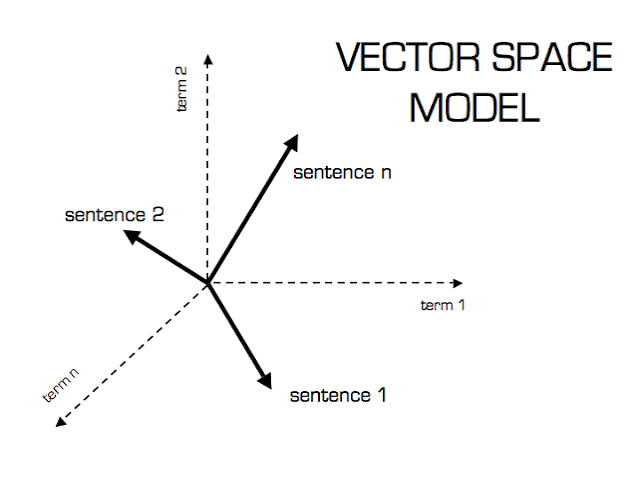

In [35]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Term-frequency representation
tf_vectorizer = CountVectorizer()

tf_matrix = tf_vectorizer.fit_transform(
    processed_text_documents
)

print("Matrix shape:", tf_matrix.shape)

Matrix shape: (10000, 65380)


In [36]:
query = "covid vaccine"

query_tf = tf_vectorizer.transform([query])

In [37]:
vsm_scores = cosine_similarity(
    query_tf,
    tf_matrix
).flatten()

In [38]:
top_indices = np.argsort(vsm_scores)[::-1][:5]

for rank, index in enumerate(top_indices, start=1):

    print(f"\nRank {rank}")
    print("Document ID:", index)
    print("Cosine Similarity:", round(vsm_scores[index], 4))
    print("Document:", documents[index][:300])


Rank 1
Document ID: 6481
Cosine Similarity: 0.7452
Document: Acceptance of a COVID-19 Vaccine Before it is Available in China During the Pandemic Objectives: China was believed to be the country with the world’s highest acceptance rate of the COVID-19 vaccine following several investigations. This study aims to explore the Chinese acceptance of a COVID-19 vac

Rank 2
Document ID: 9607
Cosine Similarity: 0.7265
Document: Acceptance and attitudes toward COVID-19 vaccines: A cross-sectional study from Jordan Vaccines are effective interventions that can reduce the high burden of diseases globally. However, public vaccine hesitancy is a pressing problem for public health authorities. With the availability of COVID-19 v

Rank 3
Document ID: 1704
Cosine Similarity: 0.712
Document: Factors Associated with COVID-19 Vaccination Intentions among Adults in the Deep South The recent approval of several COVID-19 vaccines signals progress toward controlling the pandemic. Although social distancing 

Compare the binary score and cosine similarity for the same query.

query = "covid covid vaccine"

query = "covid vaccine"

Does repeating a term affect the representation?

# TF-IDF (Term Frequency-Inverse Document Frequency) Model

Measure the importance of a term in a document relative to the entire document collection. Gives higher weights to terms that occur frequently in a document but are relatively rare across the collection.

*   TF - Measures how frequently a term occurs in a document.
*   IDF - Gives lower weight to terms appearing in many documents.
*   TF-IDF - Combines TF and IDF to represent the importance of each term.

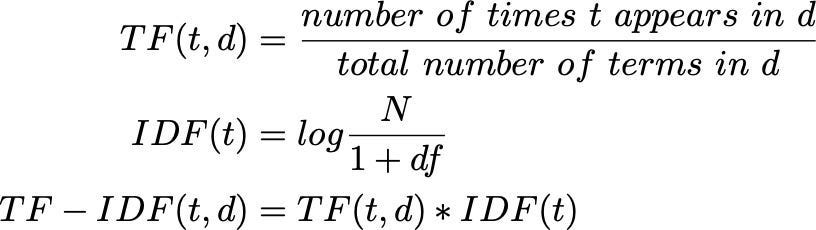

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    token_pattern=r'\b[a-zA-Z][a-zA-Z]+\b',
    min_df=2,
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    processed_text_documents
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (10000, 23223)


In [40]:
terms = tfidf_vectorizer.get_feature_names_out()

print("Number of terms:", len(terms))

print("\nFirst 20 terms:")
print(terms[:20])

Number of terms: 23223

First 20 terms:
['aa' 'aaa' 'aaaai' 'aapc' 'aas' 'aat' 'ab' 'aba' 'ababa' 'abandon'
 'abandonment' 'abate' 'abatement' 'abates' 'abbott' 'abbreviate'
 'abbreviated' 'abbreviation' 'abbvie' 'abc']


In [41]:
idf_values = tfidf_vectorizer.idf_

In [42]:
top_idf_indices = np.argsort(idf_values)[-20:][::-1]

print("Terms with highest IDF:\n")

for i in top_idf_indices:
    print(f"{terms[i]:<20} {idf_values[i]:.4f}")

Terms with highest IDF:

abbvie               9.1118
zscores              9.1118
aaa                  9.1118
zwitterionic         9.1118
abcd                 9.1118
abdominis            9.1118
zoo                  9.1118
abdominoperineal     9.1118
aas                  9.1118
multiparity          9.1118
multiparous          9.1118
multiphasic          9.1118
multitasking         9.1118
multiuse             9.1118
multiplies           9.1118
multipoles           9.1118
multipopulation      9.1118
multiport            9.1118
multiracial          9.1118
diminue              9.1118


In [43]:
lowest_idf_indices = np.argsort(idf_values)[:20]

print("Terms with lowest IDF:\n")

for i in lowest_idf_indices:
    print(f"{terms[i]:<20} {idf_values[i]:.4f}")

Terms with lowest IDF:

covid                1.5216
study                1.6610
use                  1.6686
result               1.6887
pandemic             1.9992
patient              2.0080
method               2.0287
disease              2.0771
include              2.1823
conclusion           2.1879
health               2.2656
data                 2.2677
high                 2.2691
increase             2.3717
show                 2.3788
also                 2.3956
analysis             2.3997
may                  2.4107
infection            2.4111
coronavirus          2.4310


In [44]:
query = "covid vaccine"

In [45]:
query_tfidf = tfidf_vectorizer.transform([query])

In [46]:
tfidf_scores = cosine_similarity(
    query_tfidf,
    tfidf_matrix
).flatten()

In [47]:
top_indices = np.argsort(tfidf_scores)[::-1][:5]

for rank, index in enumerate(top_indices, start=1):

    print(f"\nRank {rank}")
    print("Document ID:", index)
    print("TF-IDF Cosine Score:", round(tfidf_scores[index], 4))
    print("Document:", documents[index][:300])


Rank 1
Document ID: 5379
TF-IDF Cosine Score: 0.7003
Document: Modern vaccines and coronavirus infections Vaccines represent an outstanding success story in modern medicine and are responsible for a huge reduction in morbidity and mortality worldwide It is clear that improvements are necessary to enable the development of successful vaccines against some diffic

Rank 2
Document ID: 1170
TF-IDF Cosine Score: 0.6596
Document: A review of COVID-19 vaccines in development: 6 months into the pandemic The advent of the COVID-19 pandemic and the dynamics of its spread is unprecedented. Therefore, the need for a vaccine against the virus is huge. Researchers worldwide are working around the clock to find a vaccine. Experts est

Rank 3
Document ID: 9607
TF-IDF Cosine Score: 0.6132
Document: Acceptance and attitudes toward COVID-19 vaccines: A cross-sectional study from Jordan Vaccines are effective interventions that can reduce the high burden of diseases globally. However, public vaccine hesi

# Query Likelihood Model

Probabilistic retrieval model that ranks documents based on the likelihood of generating the given query from each document.

A document is ranked higher if its language model assigns a higher probability to the query terms.

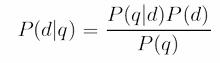

In [48]:
from collections import Counter

# Total number of terms in each document
document_lengths = [
    len(doc)
    for doc in processed_documents
]

# Collection frequency of every term
collection_counts = Counter(
    word
    for doc in processed_documents
    for word in doc
)

# Total number of terms in the collection
total_collection_terms = sum(
    collection_counts.values()
)

print("Number of documents:", len(processed_documents))
print("Total collection terms:", total_collection_terms)
print("Unique terms:", len(collection_counts))

Number of documents: 10000
Total collection terms: 1421343
Unique terms: 67131


In [49]:
import math

def query_likelihood(
    query,
    document,
    collection_counts,
    total_collection_terms,
    lambda_param=0.1
):

    document_counts = Counter(document)
    document_length = len(document)

    if document_length == 0:
        return float('-inf')

    score = 0

    query_terms = query.lower().split()

    for term in query_terms:

        # P(term | document)
        document_probability = (
            document_counts[term] / document_length
        )

        # P(term | collection)
        collection_probability = (
            collection_counts[term] /
            total_collection_terms
        )

        # Jelinek-Mercer smoothing
        probability = (
            (1 - lambda_param) * document_probability
            + lambda_param * collection_probability
        )

        # Avoid log(0)
        if probability > 0:
            score += math.log(probability)

    return score

In [50]:
query = "covid vaccine"

In [51]:
ql_scores = []

for document in processed_documents:

    score = query_likelihood(
        query,
        document,
        collection_counts,
        total_collection_terms,
        lambda_param=0.1
    )

    ql_scores.append(score)

In [52]:
import numpy as np

top_indices = np.argsort(ql_scores)[::-1][:5]

for rank, index in enumerate(top_indices, start=1):

    print(f"\nRank {rank}")
    print("Document ID:", index)
    print("QL Score:", round(ql_scores[index], 4))
    print("Document:")
    print(documents[index][:300])


Rank 1
Document ID: 7858
QL Score: -5.1462
Document:
Thrombocytopenia including immune thrombocytopenia after receipt of mRNA COVID-19 vaccines reported to the Vaccine Adverse Event Reporting System (VAERS) BACKGROUND: The objective of this study is to assess cases of thrombocytopenia, including immune thrombocytopenia (ITP), reported to the Vaccine A

Rank 2
Document ID: 2266
QL Score: -5.1592
Document:
Multiple sclerosis flare secondary to COVID-19 vaccine, a case report We report a 60-year-old lady known to have a stable MS disease. Who presented with right-hand weakness on the same day of COVID 19 vaccine administration. MRI showed a relapse, and she was treated with steroids with improvement in

Rank 3
Document ID: 3622
QL Score: -5.1592
Document:
Walking down the memory lane with SARS-CoV-2 B cells The B-cell response to COVID-19 vaccines in convalescent individuals.

Rank 4
Document ID: 6481
QL Score: -5.1783
Document:
Acceptance of a COVID-19 Vaccine Before it is Available in 

# Evaluation

In [53]:
!pip install -q ir_datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.8/947.8 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.2 MB/s eta 0:00:00


In [54]:
import ir_datasets
dataset = ir_datasets.load("cranfield")
print(dataset)

Dataset(id='cranfield', provides=['docs', 'queries', 'qrels'])


In [55]:
documents = list(dataset.docs_iter())

print("Number of documents:", len(documents))

print("\nFirst document:")
print(documents[0])

[INFO] [starting] http://ir.dcs.gla.ac.uk/resources/test_collections/cran/cran.tar.gz
[INFO] [finished] http://ir.dcs.gla.ac.uk/resources/test_collections/cran/cran.tar.gz: [00:00] [507kB] [793kB/s]


Number of documents: 1400

First document:
CranfieldDoc(doc_id='1', title='experimental investigation of the aerodynamics of a\nwing in a slipstream .', text='experimental investigation of the aerodynamics of a\nwing in a slipstream .\n  an experimental study of a wing in a propeller slipstream was\nmade in order to determine the spanwise distribution of the lift\nincrease due to slipstream at different angles of attack of the wing\nand at different free stream to slipstream velocity ratios .  the\nresults were intended in part as an evaluation basis for different\ntheoretical treatments of this problem .\n  the comparative span loading curves, together with\nsupporting evidence, showed that a substantial part of the lift increment\nproduced by the slipstream was due to a /destalling/ or\nboundary-layer-control effect .  the integrated remaining lift\nincrement, after subtracting this destalling lift, was found to agree\nwell with a potential flow theory .\n  an empirical evaluation of

In [56]:
doc_ids = [doc.doc_id for doc in documents]

texts = [doc.text for doc in documents]

print("Document ID:", doc_ids[0])
print("Text:", texts[0])

Document ID: 1
Text: experimental investigation of the aerodynamics of a
wing in a slipstream .
  an experimental study of a wing in a propeller slipstream was
made in order to determine the spanwise distribution of the lift
increase due to slipstream at different angles of attack of the wing
and at different free stream to slipstream velocity ratios .  the
results were intended in part as an evaluation basis for different
theoretical treatments of this problem .
  the comparative span loading curves, together with
supporting evidence, showed that a substantial part of the lift increment
produced by the slipstream was due to a /destalling/ or
boundary-layer-control effect .  the integrated remaining lift
increment, after subtracting this destalling lift, was found to agree
well with a potential flow theory .
  an empirical evaluation of the destalling effects was made for
the specific configuration of the experiment .


In [57]:
queries = list(dataset.queries_iter())

print("Number of queries:", len(queries))

Number of queries: 225


In [58]:
query = queries[0]

print("Query ID:", query.query_id)
print("Query:", query.text)

Query ID: 1
Query: what similarity laws must be obeyed when constructing aeroelastic models
of heated high speed aircraft .


In [59]:
def preprocess_cranfield(text):

    text = lowercase(text)
    text = remove_punctuation(text)

    tokens = tokenize(text)
    tokens = remove_stopwords(tokens)
    tokens = lemmatize_words(tokens)

    return tokens

In [60]:
processed_documents = [
    preprocess_cranfield(text)
    for text in texts
]

print("Original:")
print(texts[0][:300])

print("\nProcessed:")
print(processed_documents[0][:50])

Original:
experimental investigation of the aerodynamics of a
wing in a slipstream .
  an experimental study of a wing in a propeller slipstream was
made in order to determine the spanwise distribution of the lift
increase due to slipstream at different angles of attack of the wing
and at different free strea

Processed:
['experimental', 'investigation', 'aerodynamics', 'wing', 'slipstream', 'experimental', 'study', 'wing', 'propeller', 'slipstream', 'make', 'order', 'determine', 'spanwise', 'distribution', 'lift', 'increase', 'due', 'slipstream', 'different', 'angle', 'attack', 'wing', 'different', 'free', 'stream', 'slipstream', 'velocity', 'ratio', 'result', 'intend', 'part', 'evaluation', 'basis', 'different', 'theoretical', 'treatment', 'problem', 'comparative', 'span', 'load', 'curve', 'together', 'support', 'evidence', 'show', 'substantial', 'part', 'lift', 'increment']


In [61]:
processed_text_documents = [
    " ".join(tokens)
    for tokens in processed_documents
]

In [62]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(
    processed_text_documents
)

print("TF-IDF matrix shape:")
print(tfidf_matrix.shape)

TF-IDF matrix shape:
(1400, 7736)


In [63]:
query_tokens = preprocess_cranfield(query.text)

processed_query = " ".join(query_tokens)

print("Original Query:")
print(query.text)

print("\nProcessed Query:")
print(processed_query)

Original Query:
what similarity laws must be obeyed when constructing aeroelastic models
of heated high speed aircraft .

Processed Query:
similarity law must obey construct aeroelastic model heat high speed aircraft


In [64]:
query_vector = tfidf_vectorizer.transform(
    [processed_query]
)

print("Query vector shape:")
print(query_vector.shape)

Query vector shape:
(1, 7736)


In [65]:
from sklearn.metrics.pairwise import cosine_similarity

scores = cosine_similarity(
    query_vector,
    tfidf_matrix
).flatten()

print("Number of similarity scores:", len(scores))

Number of similarity scores: 1400


In [66]:
import numpy as np

top_indices = np.argsort(scores)[::-1][:10]

In [67]:
for rank, index in enumerate(top_indices, start=1):

    print("=" * 70)
    print("Rank:", rank)
    print("Document ID:", doc_ids[index])
    print("Cosine Similarity:", round(scores[index], 4))

    print("\nOriginal Document:")
    print(texts[index][:500])

Rank: 1
Document ID: 359
Cosine Similarity: 0.2462

Original Document:
note on the hypersonic similarity law for an unyawed
cone .
  it is now known that the hypersonic similarity law derived for
slender cones and ogival bodies under the assumption, is
applicable for mach numbers as low as 3 .  this note makes use of
a series development to infer the hypersonic similarity law for
unyawed cones from the taylor-maccoll differential equations and
associated boundary conditions .  a simple approximate formula
for the function of the similarity law is obtained,
and the 
Rank: 2
Document ID: 51
Cosine Similarity: 0.2391

Original Document:
theory of aircraft structural models subjected to aerodynamic
heating and external loads .
  the problem of investigating the simultaneous effects of transient
aerodynamic heating and external loads on aircraft structures for the
purpose of determining the ability of the structure to withstand flight
to supersonic speeds is studied .  by dimensional analys

In [68]:
qrels = list(dataset.qrels_iter())

print("Number of relevance judgments:", len(qrels))

Number of relevance judgments: 1837


In [69]:
for qrel in qrels[:10]:
    print(qrel)

TrecQrel(query_id='1', doc_id='184', relevance=2, iteration='0')
TrecQrel(query_id='1', doc_id='29', relevance=2, iteration='0')
TrecQrel(query_id='1', doc_id='31', relevance=2, iteration='0')
TrecQrel(query_id='1', doc_id='12', relevance=3, iteration='0')
TrecQrel(query_id='1', doc_id='51', relevance=3, iteration='0')
TrecQrel(query_id='1', doc_id='102', relevance=3, iteration='0')
TrecQrel(query_id='1', doc_id='13', relevance=4, iteration='0')
TrecQrel(query_id='1', doc_id='14', relevance=4, iteration='0')
TrecQrel(query_id='1', doc_id='15', relevance=4, iteration='0')
TrecQrel(query_id='1', doc_id='57', relevance=2, iteration='0')


In [70]:
from collections import defaultdict

qrels_dict = defaultdict(dict)

for qrel in qrels:

    qrels_dict[qrel.query_id][qrel.doc_id] = qrel.relevance

In [71]:
query_relevance = qrels_dict[query.query_id]

print("Relevance judgments for Query",
      query.query_id)

print(query_relevance)

Relevance judgments for Query 1
{'184': 2, '29': 2, '31': 2, '12': 3, '51': 3, '102': 3, '13': 4, '14': 4, '15': 4, '57': 2, '378': 2, '859': 2, '185': 3, '30': 3, '37': 3, '52': 4, '142': 4, '195': 4, '875': 2, '56': 3, '66': 3, '95': 3, '462': 4, '497': 3, '858': 3, '876': 3, '879': 3, '880': 3, '486': -1}


In [72]:
relevance_vector = []

for index in top_indices:

    doc_id = doc_ids[index]

    relevance = query_relevance.get(
        doc_id,
        0
    )

    if relevance > 0:
        relevance_vector.append(1)
    else:
        relevance_vector.append(0)

print("Top 10 relevance:")
print(relevance_vector)

Top 10 relevance:
[0, 1, 1, 0, 1, 0, 1, 1, 0, 0]


# Precision

In [73]:
def precision_at_k(relevance, k):

    return sum(relevance[:k]) / k

In [74]:
precision = precision_at_k(
    relevance_vector,
    10
)

print("Precision@10:",
      round(precision, 4))

Precision@10: 0.5


In [75]:
total_relevant = sum(
    1
    for relevance in query_relevance.values()
    if relevance > 0
)

print("Total relevant documents:",
      total_relevant)

Total relevant documents: 28


# Recall

In [76]:
def recall_at_k(
    relevance,
    k,
    total_relevant
):

    if total_relevant == 0:
        return 0

    return sum(relevance[:k]) / total_relevant

In [77]:
recall = recall_at_k(
    relevance_vector,
    10,
    total_relevant
)

print("Recall@10:",
      round(recall, 4))

Recall@10: 0.1786


# Average Precision

In [78]:
def average_precision(relevance):

    precision_sum = 0
    relevant_count = 0

    for rank, rel in enumerate(
        relevance,
        start=1
    ):

        if rel == 1:

            relevant_count += 1

            precision_sum += (
                relevant_count / rank
            )

    if relevant_count == 0:
        return 0

    return precision_sum / relevant_count

In [79]:
ap = average_precision(
    relevance_vector
)

print("Average Precision:",
      round(ap, 4))

Average Precision: 0.5926


# NDCG

In [80]:
relevance_grades = []

for index in top_indices:

    doc_id = doc_ids[index]

    relevance = query_relevance.get(
        doc_id,
        0
    )

    relevance_grades.append(relevance)

print("Relevance grades:")
print(relevance_grades)

Relevance grades:
[0, 3, 3, -1, 3, 0, 4, 2, 0, 0]


In [81]:
import numpy as np

def dcg_at_k(relevance, k):

    relevance = relevance[:k]

    dcg = 0

    for rank, rel in enumerate(
        relevance,
        start=1
    ):

        dcg += (
            (2 ** rel - 1)
            / np.log2(rank + 1)
        )

    return dcg

In [82]:
dcg = dcg_at_k(
    relevance_grades,
    10
)

print("DCG@10:", round(dcg, 4))

DCG@10: 16.3555


In [83]:
def idcg_at_k(relevance, k):

    ideal_relevance = sorted(
        relevance,
        reverse=True
    )

    return dcg_at_k(
        ideal_relevance,
        k
    )

In [84]:
idcg = idcg_at_k(
    relevance_grades,
    10
)

print("IDCG@10:", round(idcg, 4))

IDCG@10: 26.9473


In [85]:
def ndcg_at_k(relevance, k):

    dcg = dcg_at_k(
        relevance,
        k
    )

    idcg = idcg_at_k(
        relevance,
        k
    )

    if idcg == 0:
        return 0

    return dcg / idcg

In [86]:
ndcg = ndcg_at_k(
    relevance_grades,
    10
)

print("NDCG@10:", round(ndcg, 4))

NDCG@10: 0.6069


# Do the evaluation for a binary retrieval model
